<p style="text-align:center"><img src="../images/04_01_point_pattern.png" alt="Point Pattern Analysis" width="100%"></p>


# Hypothesis Testing and Model Extensions

Formal Monte Carlo tests of CSR, calibrated against known clustered and regular processes; the inhomogeneous K function; interaction between marked event types. This notebook is Part 1: Point Pattern Analysis (Chapter 1.4 of 5). The worked example uses Buffalo crime incidents, 2018, working subsamples of the deduplicated pattern (`data/crime_data_2018.csv`, `data/buffalo_city.shp`). The methods come from `geolattice.spatial_statistics.pointpattern`.


## Overview

Chapter 1.3's curves, Clark-Evans, G, F, J, K, L, and pair correlation, all pointed the same way: Buffalo
crime is more clustered than CSR predicts. But none of those numbers came with a rigorous significance test,
because the "expected under CSR" reference curves were theoretical formulas valid on an infinite plane, not
calibrated to *this* window, *this* sample size, or the actual sampling variability of the estimator itself.
This chapter closes that gap with **Monte Carlo hypothesis testing**, calibrates the test against patterns with
known ground truth, and extends the analysis to two questions Chapter 1.3 deliberately set aside: does the
clustering survive once the known intensity trend (Chapter 1.2) is accounted for, and do different crime types
attract or avoid each other?

| Step | What we do |
|------|------------|
| Theory | Monte Carlo simulation envelopes; pointwise bands vs global tests; two more point processes |
| Calibration | Measure the test's own size (false-positive rate) and power on patterns with known truth |
| CSR test | A formal, global Monte Carlo p-value for the real crime data |
| Inhomogeneous K | Ask whether clustering survives after removing the known citywide intensity trend |
| Cross-K | Ask whether Assault and Theft of Vehicle events co-locate more than chance predicts |

By the end you will have a properly calibrated significance test for CSR, and the tools to distinguish genuine
event-to-event interaction from an artefact of a non-constant intensity surface.


## Monte Carlo Testing: Why Simulate?

The theoretical CSR curves used in Chapter 1.3 ($\pi r^2$ for $K$, $1 - e^{-\lambda\pi r^2}$ for $G$/$F$, and so
on) describe the **expected value** of the statistic under CSR: but say nothing about how much that statistic
*varies* from one CSR realisation to the next, in a finite window, with a finite sample size, under a particular
edge correction. Two CSR patterns of the same size will not produce identical $K(r)$ curves; the question is
whether the *observed* pattern's curve is further from the theoretical line than CSR's own sampling variability
would explain.

**Conditional Monte Carlo testing** answers this directly, using exactly the CSR-equals-binomial-process
equivalence introduced in Chapter 1.1, Section 3.2:

1. Simulate $m$ CSR patterns with the same event count $n$, in the same window $W$, as the real data.
2. Compute the summary statistic (e.g. $L(r)$) on each simulated pattern, giving $m$ reference curves.
3. Compare the *observed* curve to the distribution of the $m$ simulated ones.

This is the point-pattern analogue of the conditional permutation tests used throughout the package: compare
`envelope`'s logic to the permutation machinery behind Part 2's Moran's I, or Part 4's hot-spot statistics: the
same idea (simulate the null, see where the data falls) applied to a different kind of statistic.


## Simulating Alternatives to CSR

To calibrate a test, it helps to know the truth. Two processes with known, controllable structure:

### Thomas cluster process

Introduced conceptually in Chapter 1.1; `simulate_thomas(kappa, sigma, mu, window)` implements it directly:
unobserved "parent" events form a Poisson process of intensity $\kappa$ (padded outside the window so that
clusters near the edge are not truncated), and each parent produces $\text{Poisson}(\mu)$ "offspring" scattered
around it by an isotropic Gaussian of standard deviation $\sigma$. The overall intensity is approximately
$\kappa\mu$; $\sigma$ sets the spatial scale of each cluster.

### Matérn hard-core (inhibition) process

`simulate_matern_inhibition(intensity, radius, window)` starts from a CSR pattern and **deletes** one member
of every pair closer together than `radius` (formally: each event gets a random "priority" mark, and the
lower-priority member of any too-close pair is removed): a simple model of events that compete for space and
cannot occur too close together, the regular/inhibited counterpart to Thomas clustering.


## Simulation Envelopes and Global Tests

### Pointwise vs global envelopes

`envelope(pp, statistic, nsim, alpha)` returns, at every distance $r$, the `alpha/2` and `1 - alpha/2` quantiles
of the statistic across the `nsim` simulated CSR patterns: a **pointwise envelope**, plotted as a shaded band.
It is tempting to read "the observed curve leaves the band at $r = 200$" as "significant at $r=200$", but this
commits exactly the same error as reading a LISA map without a multiple-testing correction (Part 2): checking
significance at 40 or 60 values of $r$ **simultaneously**, each nominally at level $\alpha$, inflates the
overall false-positive rate far above $\alpha$. A pointwise band is a useful *visual*, not a valid test on its
own.

### The MAD and DCLF test statistics

`EnvelopeResult.test(kind)` avoids the multiple-testing problem by collapsing the **entire curve** into a
single number before comparing to the simulations, exactly once:

- **`'mad'`** (maximum absolute deviation): $T = \max_r \big|\,\hat{f}(r) - \bar{f}_{\text{sim}}(r)\,\big|$
- **`'dclf'`** (Diggle-Cressie-Loosmore-Ford): $T = \int \big(\hat{f}(r) - \bar{f}_{\text{sim}}(r)\big)^2\, dr$

Each simulated pattern gets its own $T$ from the *same* formula (compared against the mean of the other
simulations), giving a reference distribution of $m$ values; the global p-value is the familiar
$(1 + \#\{T_{\text{sim}} \geq T_{\text{obs}}\}) / (1 + m)$. This tests "is the whole curve, taken together,
further from CSR than chance would produce?": a single, valid hypothesis test.


## Beyond a Constant Baseline: the Inhomogeneous K Function

Chapter 1.3's $K$, $L$ and $g$ all assumed a **constant** intensity $\lambda$ when computing the CSR
comparison. But Chapter 1.2 showed crime intensity is very far from constant across Buffalo. This matters:
even a process with **no genuine event-to-event interaction at all**: an *inhomogeneous Poisson process*, with
a smoothly varying $\lambda(\mathbf{s})$ but independence between events: will make the *homogeneous* $K(r)$
look inflated, simply because more points fall near each other wherever $\lambda(\mathbf{s})$ happens to be
high. Apparent "clustering" in Chapter 1.3 could, in principle, be nothing more than the known intensity trend
of Chapter 1.2, with no additional interaction at all.

The **inhomogeneous K function** (Baddeley, Møller & Waagepetersen, 2000) tests this directly, by weighting
each pair not by the constant $\hat\lambda^2$ but by the *product of the local intensities at that pair*:

$$
\hat{K}_{\text{inhom}}(r) = \sum_{i \neq j,\; d_{ij} \leq r} \frac{1}{\hat\lambda(\mathbf{s}_i)\,\hat\lambda(\mathbf{s}_j)\,\gamma(\mathbf{v}_{ij})}.
$$

Under an inhomogeneous Poisson process, *whatever* the shape of $\lambda(\mathbf{s})$, $K_{\text{inhom}}(r) =
\pi r^2$, exactly as under ordinary CSR. So any *remaining* excess above $\pi r^2$ after this adjustment is
evidence of genuine interaction between events, not just a symptom of a non-constant background rate.
`k_inhom` accepts a supplied intensity (an array, or any object with an `.at()` method such as a `KDEResult`
from Chapter 1.2) or estimates one internally from the pattern itself with a leave-one-out kernel estimate.


## Interaction Between Types: the Cross-K Function

For a *marked* pattern, `cross_k(pp, mark_i, mark_j)` asks a related but different question: do events of type
$j$ cluster around events of type $i$, more than independence between the two types would predict?

$$
K_{ij}(r) = \frac{1}{\lambda_j}\, \mathbb{E}\big[\text{number of type-}j\text{ events within } r \text{ of a
typical type-}i\text{ event}\big].
$$

Under **independent marking**: each event's type assigned independently of its location, so type $j$ events
are no more or less likely near a type $i$ event than anywhere else: $K_{ij}(r) = \pi r^2$, the same reference
curve as before. $K_{ij}(r) > \pi r^2$ suggests attraction between the types (they co-locate); $K_{ij}(r) < \pi
r^2$ suggests avoidance.

**A caveat that follows directly from Section 5**: if both crime types share the same underlying citywide
intensity trend (both are more common downtown, say), $K_{ij}$ can appear elevated with no genuine
type-to-type attraction at all: the *homogeneous* cross-K has exactly the same blind spot as the homogeneous
K of Section 5. An *inhomogeneous* cross-K would be the rigorous next step; it is not implemented in this
package, and Section 11 reports its homogeneous result with that limitation stated plainly rather than
overclaiming a causal or type-specific interpretation.


## API overview

```
- Window, PointPattern, envelope, simulate_csr, simulate_thomas, simulate_matern_inhibition, k_inhom, cross_k, intensity_at_points, ripley_k, ripley_l
```


## Setup

Locate the repository root, import the spatial-statistics helpers, and point `DATA` at the example files.

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
import geolattice.spatial_statistics
from geolattice.viz import apply_map_style

from geolattice.spatial_statistics.pointpattern import (
    Window, PointPattern, envelope, simulate_csr, simulate_thomas, simulate_matern_inhibition,
    k_inhom, cross_k, intensity_at_points, ripley_k, ripley_l,
)

apply_map_style()
C = {"blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a", "orange": "#dd6b20",
     "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b"}

print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")
print(f"data folder  : {DATA.relative_to(ROOT)}/")


geolattice.spatial_statistics : version 0.3.49
data folder  : Data/00_shared/data_spatial_stat/


## Calibrating the Test: Size and Power on Known Processes

Before trusting the test on real data, we check it on data whose truth is known: does it reject CSR about
5% of the time *when the data really are CSR* (the test's **size**), and does it reject reliably when the data
are genuinely clustered or genuinely regular (its **power**)? All three patterns here share the same $n=80$
and unit-square window, so only the generating process differs.


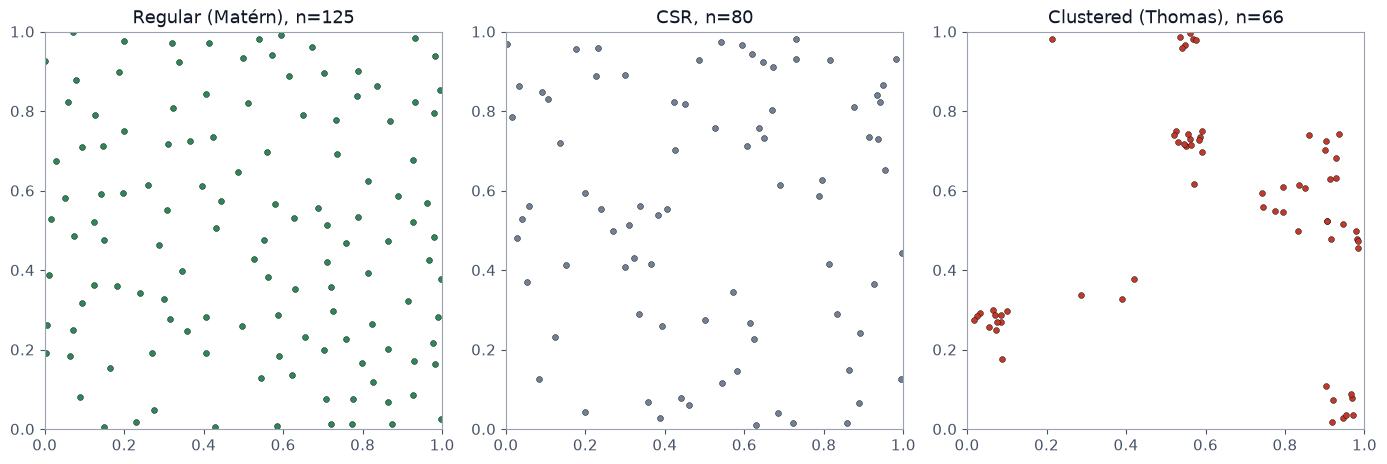

In [2]:
win_unit = Window.from_bounds(0, 0, 1, 1)
pp_csr_demo = simulate_csr(n=80, window=win_unit, seed=0)
pp_clus_demo = simulate_thomas(kappa=12, sigma=0.03, mu=7, window=win_unit, seed=0)
pp_reg_demo = simulate_matern_inhibition(intensity=300, radius=0.05, window=win_unit, seed=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, pat, title, col in zip(axes, [pp_reg_demo, pp_csr_demo, pp_clus_demo],
                               [f"Regular (Matérn), n={pp_reg_demo.n}",
                                f"CSR, n={pp_csr_demo.n}", f"Clustered (Thomas), n={pp_clus_demo.n}"],
                               [C["green"], C["grey"], C["red"]]):
    ax.scatter(pat.coords[:, 0], pat.coords[:, 1], s=18, color=col, edgecolors="k", linewidths=0.3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.set_title(title)
plt.tight_layout(); plt.show()

In [3]:
def rejection_rate(generator, n_reps=60, nsim=39, alpha=0.05, seed0=100):
    """Share of `n_reps` replicates for which the global MAD test rejects CSR at `alpha`."""
    rejections = 0
    for i in range(n_reps):
        pat = generator(seed0 + i)                          # seed for the replicate's own pattern
        env = envelope(pat, "L", nsim=nsim, seed=seed0 + i + 1000)   # independent seed for the null simulations
        rejections += env.test("mad") <= alpha
    return rejections / n_reps


size = rejection_rate(lambda s: simulate_csr(n=80, window=win_unit, seed=s))
power_clustered = rejection_rate(lambda s: simulate_thomas(12, 0.03, 7, win_unit, seed=s))
power_regular = rejection_rate(lambda s: simulate_matern_inhibition(300, 0.05, win_unit, seed=s))

calib = pd.DataFrame([
    {"scenario": "CSR (should be near the nominal 5%)", "reject at α=0.05": size},
    {"scenario": "Clustered (Thomas)", "reject at α=0.05": power_clustered},
    {"scenario": "Regular (Matérn)", "reject at α=0.05": power_regular},
]).set_index("scenario")
calib

,reject at α=0.05
scenario,
CSR (should be near the nominal 5%),0.066667
Clustered (Thomas),1.000000
Regular (Matérn),1.000000


The test's **size** (its false-positive rate under the null it claims to control) sits close to the nominal 5%
:  with 60 replicates, sampling noise alone gives a margin of roughly $\pm 3$ percentage points at this true
rate, so this is consistent with correct calibration. Its **power** against both a genuinely clustered and a
genuinely regular alternative is effectively 1.0: with this much departure from CSR, the global test never
misses it. **The same test, `envelope(..., "L").test("mad")`, is what Section 9 applies to the real data**,
now with a documented, checked false-positive rate behind it, not merely by analogy to the descriptive curves
of Chapter 1.3.


## A Formal CSR Test on the Buffalo Crime Data

We now apply exactly the same test to a 1,500-event subsample of the deduplicated Buffalo pattern (Chapter
1.3's rationale for deduplication and subsampling both apply here: `envelope`'s cost scales with both the
pattern size and the number of simulations).


working sample : n = 1,500
global MAD test  : p = 0.010
global DCLF test : p = 0.010
(smallest reportable p with 99 simulations: 0.010)


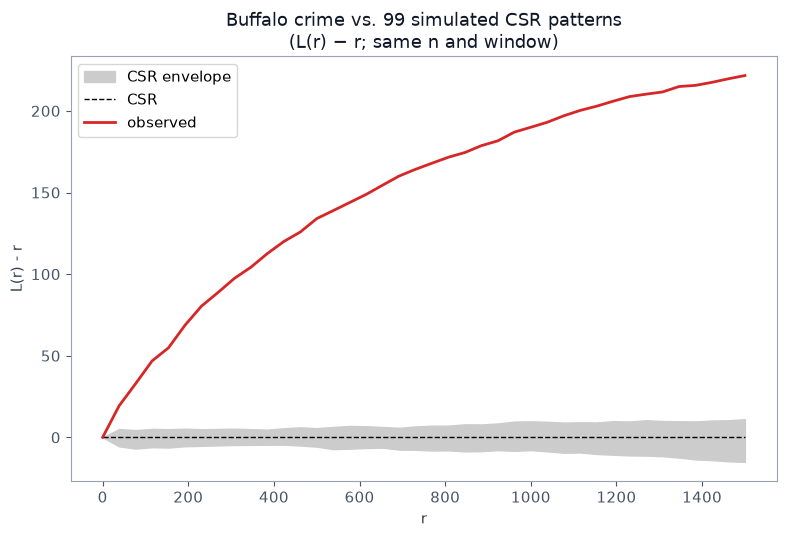

In [4]:
from pyproj import Transformer

tbl = pd.read_csv(DATA / "crime_data_2018.csv")
city = gpd.read_file(DATA / "buffalo_city.shp")
CRS_CORRECT = 26917
city_fixed = city.to_crs(4326).to_crs(CRS_CORRECT)
transformer = Transformer.from_crs(4326, CRS_CORRECT, always_xy=True)
x_m, y_m = transformer.transform(tbl["long"].to_numpy(), tbl["lat"].to_numpy())
coords_all = np.column_stack([x_m, y_m])
win_city = Window.from_gdf(city_fixed)
pp_dedup = PointPattern(coords_all, window=win_city, marks=tbl["incident_type"].to_numpy(),
                        clip=True).deduplicate()

rng = np.random.default_rng(11)
pp_test = pp_dedup.subset(rng.choice(pp_dedup.n, 1500, replace=False))
r_range = np.linspace(0, 1500, 40)

env_real = envelope(pp_test, "L", nsim=99, r=r_range, seed=11)

print(f"working sample : n = {pp_test.n:,}")
print(f"global MAD test  : p = {env_real.test('mad'):.3f}")
print(f"global DCLF test : p = {env_real.test('dclf'):.3f}")
print(f"(smallest reportable p with 99 simulations: {1 / 100:.3f})")

fig, ax = plt.subplots(figsize=(8, 5.5))
env_real.plot(ax=ax, lw=2)   # EnvelopeResult.plot() colours the observed curve itself; no color= kwarg
ax.set_title("Buffalo crime vs. 99 simulated CSR patterns\n(L(r) − r; same n and window)")
plt.tight_layout(); plt.show()

Both global tests reach the smallest p-value that 99 simulations can report: the observed curve never comes
close to the simulated CSR envelope at any distance. Combined with the calibration in Section 8 (a test that
correctly controls its false-positive rate and reliably detects real departures), this is now a properly
supported conclusion, not just a descriptive impression: **Buffalo crime departs from complete spatial
randomness far beyond anything sampling variability could produce.**


## Does Intensity Explain the Clustering? The Inhomogeneous K Function

Section 9's test, like all of Chapter 1.3, compared the data to a *constant-intensity* CSR baseline, which
Chapter 1.2 already showed is the wrong baseline for this city. We now compare the **homogeneous** and
**inhomogeneous** K functions on the same subsample, to see how much of the apparent clustering the known
intensity trend can explain away.


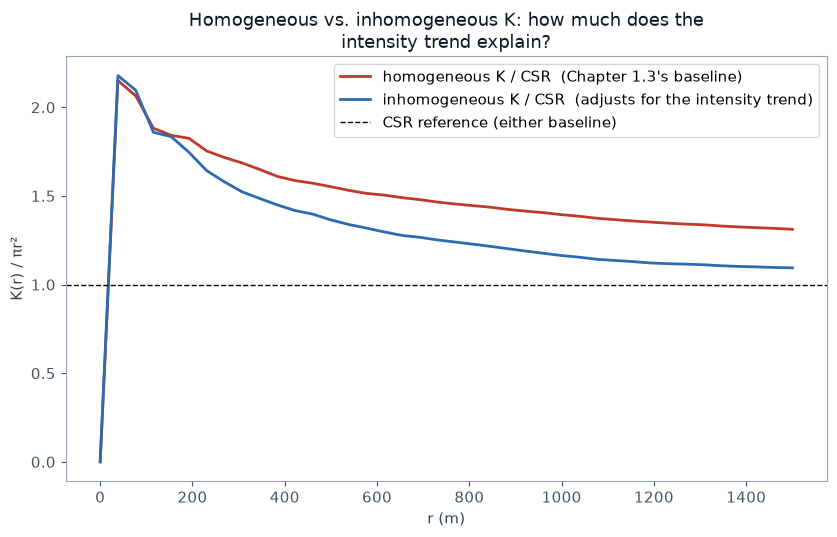

r =   192 m :  homogeneous 1.82×CSR   inhomogeneous 1.75×CSR   (intensity trend explains 10% of the excess)
r =   577 m :  homogeneous 1.51×CSR   inhomogeneous 1.32×CSR   (intensity trend explains 38% of the excess)
r =  1154 m :  homogeneous 1.36×CSR   inhomogeneous 1.13×CSR   (intensity trend explains 64% of the excess)
r =  1500 m :  homogeneous 1.31×CSR   inhomogeneous 1.09×CSR   (intensity trend explains 70% of the excess)


In [5]:
rng2 = np.random.default_rng(3)
pp_inhom = pp_dedup.subset(rng2.choice(pp_dedup.n, 2000, replace=False))

lam_at_events = intensity_at_points(pp_inhom, leave_one_out=True)   # kernel intensity, self excluded
k_hom = ripley_k(pp_inhom, r_range)
k_ih = k_inhom(pp_inhom, intensity=lam_at_events, r=r_range)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(r_range, k_hom.estimate / np.where(k_hom.theoretical == 0, 1, k_hom.theoretical),
        color=C["red"], lw=2, label="homogeneous K / CSR  (Chapter 1.3's baseline)")
ax.plot(r_range, k_ih.estimate / np.where(k_ih.theoretical == 0, 1, k_ih.theoretical),
        color=C["blue"], lw=2, label="inhomogeneous K / CSR  (adjusts for the intensity trend)")
ax.axhline(1.0, color="k", ls="--", lw=1, label="CSR reference (either baseline)")
ax.set_xlabel("r (m)"); ax.set_ylabel("K(r) / πr²")
ax.set_title("Homogeneous vs. inhomogeneous K: how much does the\nintensity trend explain?")
ax.legend()
plt.tight_layout(); plt.show()

for i in [5, 15, 30, 39]:
    hr = k_hom.estimate[i] / k_hom.theoretical[i]
    ir = k_ih.estimate[i] / k_ih.theoretical[i]
    print(f"r = {r_range[i]:5.0f} m :  homogeneous {hr:.2f}×CSR   inhomogeneous {ir:.2f}×CSR   "
          f"(intensity trend explains {100 * (hr - ir) / (hr - 1):.0f}% of the excess)")

Adjusting for the known intensity surface **reduces** the apparent clustering at every distance, and the
reduction is proportionally larger at long range than at short range: by $r \approx 1{,}500$ m, the known
citywide intensity trend explains most of the remaining homogeneous excess. But the inhomogeneous curve stays
**above 1 at every distance shown**, especially at short range: so intensity variation is a real part of the
story, but not the whole of it. Some genuine event-to-event clustering: beyond what "some places just have
more opportunity" predicts: survives even after the adjustment, concentrated at the same short range that
Chapter 1.3's pair correlation function pointed to.


## Do Assault and Vehicle Theft Co-locate? The Cross-K Function

As a final, more exploratory question: does one crime type occur near another more than independence would
predict? We compare Assault and Theft of Vehicle, two offence types with plausibly different typical settings.


Assault             398
Theft of Vehicle    173
Name: count, dtype: int64


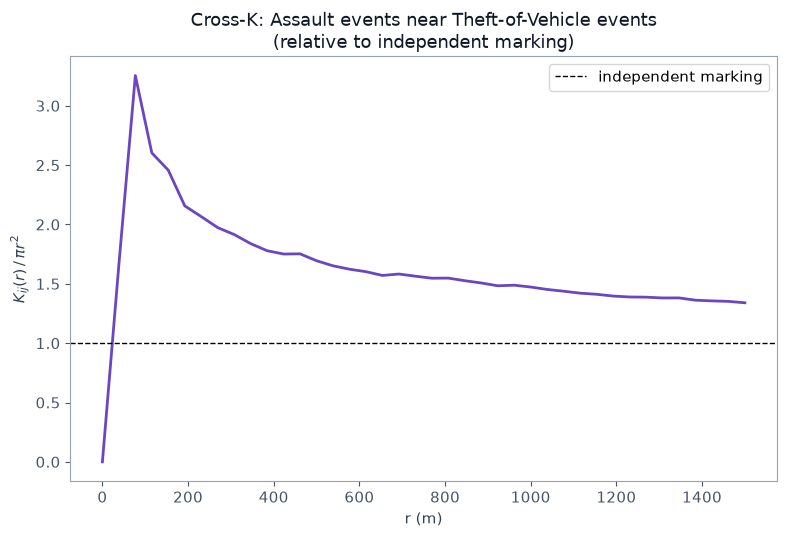

K_ij(r) at r = 300 m is 1.92× the independent-marking reference


In [6]:
mask = np.isin(pp_inhom.marks, ["Assault", "Theft of Vehicle"])
pp_two = pp_inhom.subset(mask)
print(pd.Series(pp_two.marks).value_counts())

ck = cross_k(pp_two, "Assault", "Theft of Vehicle", r_range)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(ck.r, ck.estimate / np.where(ck.theoretical == 0, 1, ck.theoretical), color=C["purple"], lw=2)
ax.axhline(1.0, color="k", ls="--", lw=1, label="independent marking")
ax.set_xlabel("r (m)"); ax.set_ylabel(r"$K_{ij}(r)\,/\,\pi r^2$")
ax.set_title("Cross-K: Assault events near Theft-of-Vehicle events\n(relative to independent marking)")
ax.legend()
plt.tight_layout(); plt.show()

ratio_300 = float(ck.estimate[np.searchsorted(r_range, 300)] / ck.theoretical[np.searchsorted(r_range, 300)])
print(f"K_ij(r) at r = 300 m is {ratio_300:.2f}× the independent-marking reference")

Assault and Theft of Vehicle events sit closer together than independent marking would predict, at every
distance checked. **This does not, on its own, establish that the two crime types attract each other**: as
Section 6 warned, and Section 10 just demonstrated directly for the single-type case, a shared underlying
intensity trend (both offences more common in the same commercial and nightlife areas, say) can produce exactly
this signature with no type-specific interaction at all. Confirming a genuine type-to-type effect would need an
inhomogeneous cross-K, adjusting each type by its own estimated intensity: the natural next step, and, as
noted, one this package does not yet implement.


## A Bridge to Time: Marks by Day of Week

Every function in this chapter has treated 2018 as a single, timeless snapshot. The data carry a `day_of_week`
field that hints at a temporal dimension worth flagging, even though a full treatment is out of scope here
(the companion `hour_of_day` field is a coarse 12-level bucket code, not a genuine 24-hour clock time, and is
not reliable enough to analyse spatially).


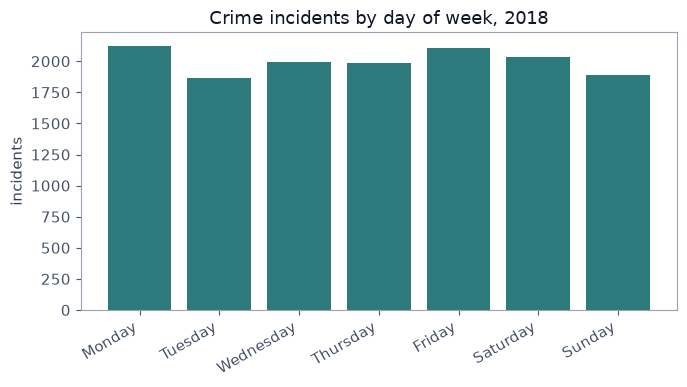

weekday incidents : 10,077  (72.0%)
weekend incidents : 3,924  (28.0%, vs 2/7 = 28.6% if days were equal)


In [7]:
day_counts = tbl["day_of_week"].value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(day_counts.index, day_counts.values, color=C["teal"])
ax.set_ylabel("incidents"); ax.set_title("Crime incidents by day of week, 2018")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()

weekend = tbl["day_of_week"].isin(["Saturday", "Sunday"])
print(f"weekday incidents : {(~weekend).sum():,}  ({100 * (~weekend).mean():.1f}%)")
print(f"weekend incidents : {weekend.sum():,}  ({100 * weekend.mean():.1f}%, vs 2/7 = 28.6% if days were equal)")

Counts are fairly level across the week, with a modest lift on Friday and Saturday: plausible, and worth a
formal test. Doing that test properly (e.g. a space-time K-function, or comparing the spatial pattern on
weekdays against weekends) needs machinery this chapter does not have: a way to treat time as a genuine third
dimension of the point process, not just another mark. That is exactly **Part 9 (Spatio-Temporal Analysis)**,
and this small chart is its first preview.


## Summary and Conclusions

### What we did

1. Explained why Monte Carlo simulation, not the theoretical CSR formulas alone, is needed to attach a valid
   p-value to a summary-function curve: and how conditional simulation licenses it.
2. Introduced two more point processes with controllable, known structure: Thomas clustering and Matérn
   inhibition.
3. Distinguished pointwise envelopes (a visual, vulnerable to the same multiple-testing problem as an
   unadjusted LISA map) from global MAD/DCLF tests (a single, valid p-value per pattern).
4. **Calibrated** the global test on synthetic data: its false-positive rate matched its nominal level, and its
   power against both clustered and regular alternatives was effectively 1.0.
5. Applied the calibrated test to the real Buffalo data: both global tests reached the smallest p-value 99
   simulations can report.
6. Introduced the **inhomogeneous K function**, and showed that Chapter 1.2's known intensity trend explains
   away much, but not all, of the apparent clustering, concentrated more at long range than short.
7. Introduced the **cross-K function**, found apparent co-location between Assault and Theft of Vehicle, and
   flagged, using the lesson just learned from the single-type case, that this cannot yet be told apart from
   a shared intensity trend with this package's tools.
8. Previewed the **temporal** dimension (day of week) as a bridge to Part 9.

### Practical takeaways

- **Never read significance off a pointwise envelope.** Use `EnvelopeResult.test('mad')` or `'dclf'` for a
  single, valid p-value; reserve the shaded band for visual intuition.
- **Calibrate before you trust.** A test's size and power on data with known truth is cheap to check and
  directly tells you whether to believe its output on data where the truth is exactly what you are trying to
  learn.
- **"Clustered" is not one claim: it is (at least) two.** Elevated density where the process happens to have
  higher intensity is not the same phenomenon as events attracting each other conditional on that intensity.
  The inhomogeneous K function is how you tell them apart, and Section 10 shows both effects can be present
  at once, at different spatial scales.
- The same logic applies to marks: an elevated cross-K between two event types is consistent with genuine
  interaction *or* with both types sharing a hot spot: distinguishing them needs an inhomogeneous cross-K,
  which is a documented gap here, not a result to be overclaimed.

### Next steps

**Chapter 1.5 (Integration with Areal Analysis, Pitfalls and Exercises)** closes Part 1 by aggregating these
same point events into the 35 Buffalo neighbourhood polygons, connecting point pattern analysis to the areal
(lattice) methods of Part 2, working through the accumulated pitfalls of the whole Part, and a set of solved
exercises.


## Further reading

### Textbooks

| Reference | Notes |
|---|---|
| Baddeley, A., Rubak, E. & Turner, R. (2015). *Spatial Point Patterns: Methodology and Applications with R*. CRC Press. | Chapters 10 (envelopes and Monte Carlo tests) and 15 (inhomogeneous summary statistics) |
| Diggle, P. J. (2013). *Statistical Analysis of Spatial and Spatio-Temporal Point Patterns* (3rd ed.). CRC Press. | Monte Carlo testing, cluster processes, multitype patterns |
| Illian, J., Penttinen, A., Stoyan, H. & Stoyan, D. (2008). *Statistical Analysis and Modelling of Spatial Point Patterns*. Wiley. | Thomas and Matérn processes in depth |
| Davison, A. C. & Hinkley, D. V. (1997). *Bootstrap Methods and Their Application*. Cambridge University Press. | General Monte Carlo / resampling test theory underlying Section 4 |

### Key papers

| Paper | Contribution |
|---|---|
| Besag, J. & Diggle, P. J. (1977). Simple Monte Carlo tests for spatial pattern. *Applied Statistics*, 26, 327-333. | Origin of the Monte Carlo envelope test |
| Loosmore, N. B. & Ford, E. D. (2006). Statistical inference using the G or K point pattern spatial statistics. *Ecology*, 87, 1925-1931. | The DCLF-style global test statistic |
| Baddeley, A., Møller, J. & Waagepetersen, R. (2000). Non- and semi-parametric estimation of interaction in inhomogeneous point patterns. *Statistica Neerlandica*, 54, 329-350. | The inhomogeneous K function of Section 5 |
| Matérn, B. (1960). *Spatial Variation*. Meddelanden från Statens Skogsforskningsinstitut. | The hard-core inhibition process |

### In this library

| Object | Role |
|---|---|
| `geolattice.spatial_statistics.pointpattern.envelope` | Monte Carlo simulation envelope; `.test('mad'/'dclf')` for a global p-value |
| `geolattice.spatial_statistics.pointpattern.simulate_thomas`, `simulate_matern_inhibition` | Known clustered / regular alternatives to CSR |
| `geolattice.spatial_statistics.pointpattern.k_inhom` | Inhomogeneous K function, adjusted for a known or estimated intensity |
| `geolattice.spatial_statistics.pointpattern.cross_k` | Bivariate (cross-type) K function |
| `geolattice.spatial_statistics.pointpattern.intensity_at_points` | Leave-one-out kernel intensity at each event (feeds `k_inhom`) |
| Chapter 1.2 | Intensity estimation (`kde`), the surface this chapter tests against |
| Chapter 1.3 | The descriptive curves this chapter turns into formal tests |
| Chapter 1.5 | Bridging points to areal (lattice) analysis; pitfalls and exercises |
